# Setup

In [152]:
# Cloning github repo
!git clone https://github.com/JoshuaDSah/CP101_FP.git /content/CP101_FP

fatal: destination path '/content/CP101_FP' already exists and is not an empty directory.


In [153]:
# Installing needed packages
%cd /content/CP101_FP
!pip install -r requirements.txt

/content/CP101_FP


In [154]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import contextily as cx
import os
from matplotlib.colors import LogNorm

from lonboard import Map, PolygonLayer, SolidPolygonLayer
from lonboard.basemap import MaplibreBasemap, CartoStyle
from lonboard.colormap import apply_continuous_cmap, apply_categorical_cmap
from lonboard import viz

from palettable.colorbrewer.sequential import YlGnBu_9

In [155]:
visualizations_folder = "visualizations"
os.makedirs(visualizations_folder, exist_ok=True)

## Loading In CA Block Group Shapefiles

In [156]:
ca_bg = gpd.read_file("data/raw/tl_2026_06_bg")

In [157]:
ca_bg.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,GEOID,GEOIDFQ,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,06,103,000300,3,061030003003,1500000US061030003003,Block Group 3,G5030,S,1187540563,9004997,+39.8846521,-122.5865126,"POLYGON ((-122.96009 39.84524, -122.96009 39.8..."
1,06,103,001101,2,061030011012,1500000US061030011012,Block Group 2,G5030,S,120925509,328617,+39.8673881,-122.2228333,"POLYGON ((-122.27552 39.83011, -122.27557 39.8..."
2,06,103,000701,3,061030007013,1500000US061030007013,Block Group 3,G5030,S,667165,0,+40.1662008,-122.2271313,"POLYGON ((-122.23392 40.17015, -122.23272 40.1..."
3,06,103,000702,2,061030007022,1500000US061030007022,Block Group 2,G5030,S,5850919,0,+40.1451977,-122.2506272,"POLYGON ((-122.27129 40.12865, -122.27128 40.1..."
4,06,103,000701,2,061030007012,1500000US061030007012,Block Group 2,G5030,S,1261051,0,+40.1644631,-122.2390521,"POLYGON ((-122.25666 40.16318, -122.25573 40.1..."


In [158]:
ca_bg.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 25607 entries, 0 to 25606
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   25607 non-null  object  
 1   COUNTYFP  25607 non-null  object  
 2   TRACTCE   25607 non-null  object  
 3   BLKGRPCE  25607 non-null  object  
 4   GEOID     25607 non-null  object  
 5   GEOIDFQ   25607 non-null  object  
 6   NAMELSAD  25607 non-null  object  
 7   MTFCC     25607 non-null  object  
 8   FUNCSTAT  25607 non-null  object  
 9   ALAND     25607 non-null  int64   
 10  AWATER    25607 non-null  int64   
 11  INTPTLAT  25607 non-null  object  
 12  INTPTLON  25607 non-null  object  
 13  geometry  25607 non-null  geometry
dtypes: geometry(1), int64(2), object(11)
memory usage: 2.7+ MB


In [159]:
# Create a copy for cleaning
ca_bg_clean = ca_bg.copy()

# Standardize column names
ca_bg_clean.columns = ca_bg_clean.columns.str.strip().str.lower()

# Removing whitespace for each column
for column in ca_bg_clean.columns:
  if ca_bg_clean[column].dtype == 'object':
    ca_bg_clean[column] = ca_bg_clean[column].str.strip()

# Display cleaned dataset
ca_bg_clean.head()

,statefp,countyfp,tractce,blkgrpce,geoid,geoidfq,namelsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,06,103,000300,3,061030003003,1500000US061030003003,Block Group 3,G5030,S,1187540563,9004997,+39.8846521,-122.5865126,"POLYGON ((-122.96009 39.84524, -122.96009 39.8..."
1,06,103,001101,2,061030011012,1500000US061030011012,Block Group 2,G5030,S,120925509,328617,+39.8673881,-122.2228333,"POLYGON ((-122.27552 39.83011, -122.27557 39.8..."
2,06,103,000701,3,061030007013,1500000US061030007013,Block Group 3,G5030,S,667165,0,+40.1662008,-122.2271313,"POLYGON ((-122.23392 40.17015, -122.23272 40.1..."
3,06,103,000702,2,061030007022,1500000US061030007022,Block Group 2,G5030,S,5850919,0,+40.1451977,-122.2506272,"POLYGON ((-122.27129 40.12865, -122.27128 40.1..."
4,06,103,000701,2,061030007012,1500000US061030007012,Block Group 2,G5030,S,1261051,0,+40.1644631,-122.2390521,"POLYGON ((-122.25666 40.16318, -122.25573 40.1..."


In [160]:
# Looking at ca_bg_clean info
ca_bg_clean.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 25607 entries, 0 to 25606
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   statefp   25607 non-null  object  
 1   countyfp  25607 non-null  object  
 2   tractce   25607 non-null  object  
 3   blkgrpce  25607 non-null  object  
 4   geoid     25607 non-null  object  
 5   geoidfq   25607 non-null  object  
 6   namelsad  25607 non-null  object  
 7   mtfcc     25607 non-null  object  
 8   funcstat  25607 non-null  object  
 9   aland     25607 non-null  int64   
 10  awater    25607 non-null  int64   
 11  intptlat  25607 non-null  object  
 12  intptlon  25607 non-null  object  
 13  geometry  25607 non-null  geometry
dtypes: geometry(1), int64(2), object(11)
memory usage: 2.7+ MB


## Filtering Block Groups to SF County & Santa Clara County

In [161]:
sf_sc_bg = ca_bg_clean[(ca_bg_clean['countyfp'] == '075') | (ca_bg_clean['countyfp'] == '085')]

sf_sc_bg.head()

,statefp,countyfp,tractce,blkgrpce,geoid,geoidfq,namelsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,0,+37.2959111,-121.8469592,"POLYGON ((-121.85252 37.29464, -121.85243 37.2..."
18,06,085,503218,2,060855032182,1500000US060855032182,Block Group 2,G5030,S,183484,0,+37.2804060,-121.8340967,"POLYGON ((-121.8373 37.27992, -121.83723 37.27..."
19,06,085,504424,2,060855044242,1500000US060855044242,Block Group 2,G5030,S,370668,0,+37.4448467,-121.8829137,"POLYGON ((-121.88762 37.44776, -121.88738 37.4..."
20,06,085,512309,1,060855123091,1500000US060855123091,Block Group 1,G5030,S,2908327,0,+37.1388946,-121.5954451,"POLYGON ((-121.61035 37.13042, -121.60986 37.1..."
21,06,085,512036,2,060855120362,1500000US060855120362,Block Group 2,G5030,S,472203,0,+37.2388299,-121.8108181,"POLYGON ((-121.81728 37.24107, -121.81717 37.2..."


In [162]:
# Looking at sf_sc_bg info and length
sf_sc_bg.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 1854 entries, 17 to 25507
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   statefp   1854 non-null   object  
 1   countyfp  1854 non-null   object  
 2   tractce   1854 non-null   object  
 3   blkgrpce  1854 non-null   object  
 4   geoid     1854 non-null   object  
 5   geoidfq   1854 non-null   object  
 6   namelsad  1854 non-null   object  
 7   mtfcc     1854 non-null   object  
 8   funcstat  1854 non-null   object  
 9   aland     1854 non-null   int64   
 10  awater    1854 non-null   int64   
 11  intptlat  1854 non-null   object  
 12  intptlon  1854 non-null   object  
 13  geometry  1854 non-null   geometry
dtypes: geometry(1), int64(2), object(11)
memory usage: 281.8+ KB


In [163]:
print("Rows lost after filtering to block groups in SF & SCC only:", len(ca_bg_clean) - len(sf_sc_bg))

Rows lost after filtering to block groups in SF & SCC only: 23753


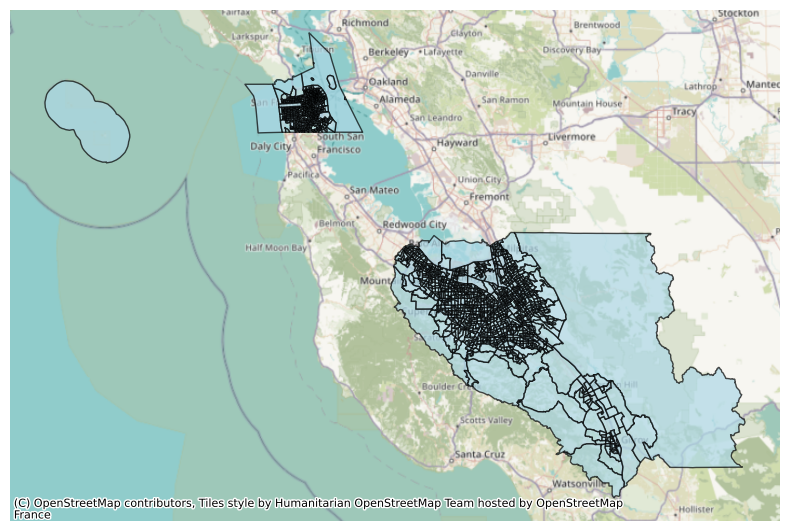

In [164]:
# Plotting block groups as a visual check
fig, ax = plt.subplots(figsize=(8, 8))
sf_sc_bg.plot(edgecolor="black", facecolor="lightblue", alpha=0.7, legend=True, ax=ax)
cx.add_basemap(ax, crs=sf_sc_bg.crs)
ax.set_axis_off()

plt.tight_layout()
plt.show()

# Functions

In [165]:
# Creating function to count number of routes by unique ID (geoid or zoneid)
def calculate_route_density(geo_df, route_data, unique_id):

  # Calculating number of routes by unique ID
  route_counts = route_data.groupby(unique_id)['index_right'].count()
  geo_df['route_count'] = (geo_df[unique_id].map(route_counts).fillna(0))

  # Creating area column
  geo_df['area_sqmile'] = geo_df.geometry.area / 27878400

  # Calculating route_density
  geo_df['route_density'] = (geo_df['route_count'] / geo_df['area_sqmile'])

  return geo_df.head()

In [166]:
# Creating function to map route density
def map_route_density(geo_df):
  positive_route_density = geo_df[geo_df['route_density'] > 0]

  fig, ax = plt.subplots(figsize=(9, 9))
  geo_df.plot(column = 'route_density',
                legend = True,
                legend_kwds={'label': 'Transit Routes per Square Mile (log scale)'},
                ax=ax,
                cmap="YlGnBu",
                edgecolor="white",
                linewidth=0.1,
                norm=LogNorm(
                    vmin=positive_route_density["route_density"].min(),
                    vmax=positive_route_density["route_density"].max()),
                )
  return fig, ax

In [167]:
# Creating function to create a histogram of route density
def create_histogram(geo_df):
  fig, ax = plt.subplots(figsize=(8, 8))
  geo_df['route_density'].plot.hist(edgecolor = 'black', bins = 50)

  plt.xlabel('Transit Routes per Square Mile per Block Group')

  return fig, ax

In [168]:
# Creating function to calculate route density statistics
def calc_stats(geo_df, area_name, area_type):
  # Calculating route_density median
  print("Median route density:", geo_df['route_density'].median())

  # Calculating route density average per area/region
  print('-'*60)
  print("Route Density Average Per", area_type)
  print(geo_df.groupby(area_name)['route_density'].mean())

  # Calculating route density median per area/region
  print('-'*60)
  print("Route Density Median Per", area_type)
  print(geo_df.groupby(area_name)['route_density'].median())

# Transit Route Density Analysis

In [169]:
# Loading in cleaned transit route dataset
transit_routes = gpd.read_file("data/processed/transit_routes_cleaned.csv")

# Checking data types
transit_routes.info()

# Converting geometry from cleaned dataset to an active geometry column
transit_routes["geometry"] = gpd.GeoSeries.from_wkt(transit_routes["geometry"])

# Converting to GeoDataFrame
transit_routes = gpd.GeoDataFrame(transit_routes, geometry="geometry", crs="EPSG:2227")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   objectid     501 non-null    object
 1   shape_id     501 non-null    object
 2   route_name   501 non-null    object
 3   n_trips      501 non-null    object
 4   route_type   501 non-null    object
 5   route_leng   501 non-null    object
 6   route_id     501 non-null    object
 7   pct_route_   501 non-null    object
 8   shn_route    501 non-null    object
 9   agency       501 non-null    object
 10  district_n   501 non-null    object
 11  shape_leng   501 non-null    object
 12  geometry     501 non-null    object
 13  index_right  501 non-null    object
 14  fipst        501 non-null    object
 15  fipco        501 non-null    object
 16  coname       501 non-null    object
dtypes: object(17)
memory usage: 66.7+ KB


In [170]:
# Confirming geometry was converted
print(transit_routes['geometry'].dtype)

geometry


## Spatial Join of Cleaned Transit Route & Census Blocks Dataset

In [171]:
# Changing datasets to the same CRS
transit_routes = transit_routes.to_crs("EPSG:2227")

sf_sc_bg = sf_sc_bg.to_crs("EPSG:2227")

In [172]:
# Spatial join of transit routes & census blocks
routes_sf_sc = gpd.sjoin(sf_sc_bg, transit_routes.drop(columns=["index_right"]), how = "left", predicate = "intersects")

# Display joined data
routes_sf_sc.head()

,statefp,countyfp,tractce,blkgrpce,geoid,geoidfq,namelsad,mtfcc,funcstat,aland,...,route_leng,route_id,pct_route_,shn_route,agency,district_n,shape_leng,fipst,fipco,coname
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,...,161043.57,Rapid 568,1.6,"85, 87, 152, 280",Santa Clara Valley Transportation Authority,04 - Bay Area / Oakland,61673.358112349415,06,085,
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,...,162999.68,Rapid 568,1.6,"85, 87, 152, 280",Santa Clara Valley Transportation Authority,04 - Bay Area / Oakland,62423.60660706332,06,085,
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,...,173947.47,68,1.4,"85, 87, 152, 280",Santa Clara Valley Transportation Authority,04 - Bay Area / Oakland,66615.96077218154,06,085,
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,...,169442.35,68,1.5,"85, 87, 152, 280",Santa Clara Valley Transportation Authority,04 - Bay Area / Oakland,64889.236294291644,06,085,
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,...,49207.11,73,0.4,280,Santa Clara Valley Transportation Authority,04 - Bay Area / Oakland,18873.280013663963,06,085,


In [173]:
# Looking at data types in routes_sf_sc and length
routes_sf_sc.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 13612 entries, 17 to 25507
Data columns (total 30 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   statefp      13612 non-null  object  
 1   countyfp     13612 non-null  object  
 2   tractce      13612 non-null  object  
 3   blkgrpce     13612 non-null  object  
 4   geoid        13612 non-null  object  
 5   geoidfq      13612 non-null  object  
 6   namelsad     13612 non-null  object  
 7   mtfcc        13612 non-null  object  
 8   funcstat     13612 non-null  object  
 9   aland        13612 non-null  int64   
 10  awater       13612 non-null  int64   
 11  intptlat     13612 non-null  object  
 12  intptlon     13612 non-null  object  
 13  geometry     13612 non-null  geometry
 14  index_right  13427 non-null  float64 
 15  objectid     13427 non-null  object  
 16  shape_id     13427 non-null  object  
 17  route_name   13427 non-null  object  
 18  n_trips      13427 non

In [174]:
print("Number of block groups (SF & SCC):", len(sf_sc_bg))
print("Transit routes in SF & SCC:", len(transit_routes))
print("Spatial join:", len(routes_sf_sc))

Number of block groups (SF & SCC): 1854
Transit routes in SF & SCC: 501
Spatial join: 13612


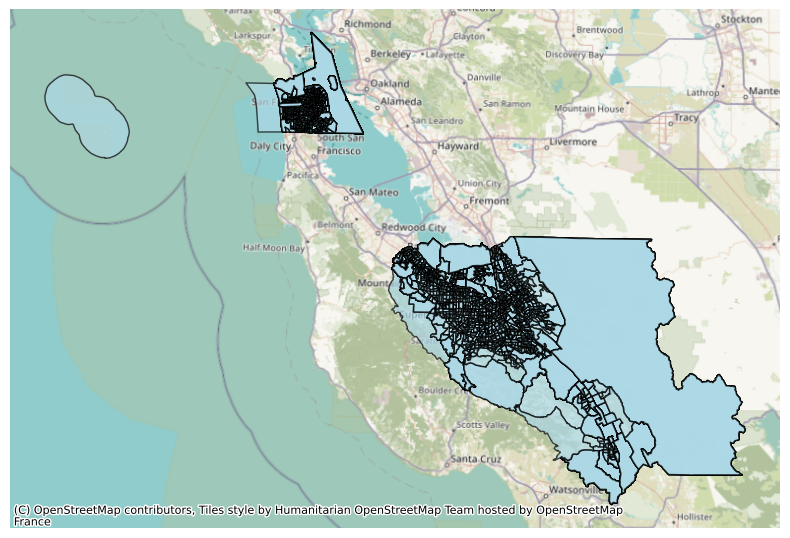

In [175]:
# Looking at spatial join map as a visual check
fig, ax = plt.subplots(figsize=(8, 8))
routes_sf_sc.plot(edgecolor="black", facecolor="lightblue", alpha=0.7, legend=True, ax=ax)
cx.add_basemap(ax, crs=sf_sc_bg.crs)
ax.set_axis_off()

plt.tight_layout()
plt.show()

## Calculating Transit Route Density

In [176]:
# Counting number of routes in each block and calculating transit route desnity
calculate_route_density(sf_sc_bg, routes_sf_sc, 'geoid')

,statefp,countyfp,tractce,blkgrpce,geoid,geoidfq,namelsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry,route_count,area_sqmile,route_density
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,0,+37.2959111,-121.8469592,"POLYGON ((6168245.665 1932597.855, 6168271.645...",8,0.162324,49.283999
18,06,085,503218,2,060855032182,1500000US060855032182,Block Group 2,G5030,S,183484,0,+37.2804060,-121.8340967,"POLYGON ((6172595.092 1927174.469, 6172615.108...",14,0.070838,197.633611
19,06,085,504424,2,060855044242,1500000US060855044242,Block Group 2,G5030,S,370668,0,+37.4448467,-121.8829137,"POLYGON ((6158862.22 1988490.311, 6158933.18 1...",4,0.143099,27.952672
20,06,085,512309,1,060855123091,1500000US060855123091,Block Group 1,G5030,S,2908327,0,+37.1388946,-121.5954451,"POLYGON ((6237974.743 1871880.408, 6238118.981...",0,1.122875,0.000000
21,06,085,512036,2,060855120362,1500000US060855120362,Block Group 2,G5030,S,472203,0,+37.2388299,-121.8108181,"POLYGON ((6178220.758 1912947.865, 6178253.057...",5,0.182307,27.426330


In [177]:
# Checking info of sf_sc_bg
sf_sc_bg.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 1854 entries, 17 to 25507
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   statefp        1854 non-null   object  
 1   countyfp       1854 non-null   object  
 2   tractce        1854 non-null   object  
 3   blkgrpce       1854 non-null   object  
 4   geoid          1854 non-null   object  
 5   geoidfq        1854 non-null   object  
 6   namelsad       1854 non-null   object  
 7   mtfcc          1854 non-null   object  
 8   funcstat       1854 non-null   object  
 9   aland          1854 non-null   int64   
 10  awater         1854 non-null   int64   
 11  intptlat       1854 non-null   object  
 12  intptlon       1854 non-null   object  
 13  geometry       1854 non-null   geometry
 14  route_count    1854 non-null   int64   
 15  area_sqmile    1854 non-null   float64 
 16  route_density  1854 non-null   float64 
dtypes: float64(2), geometry(1), 

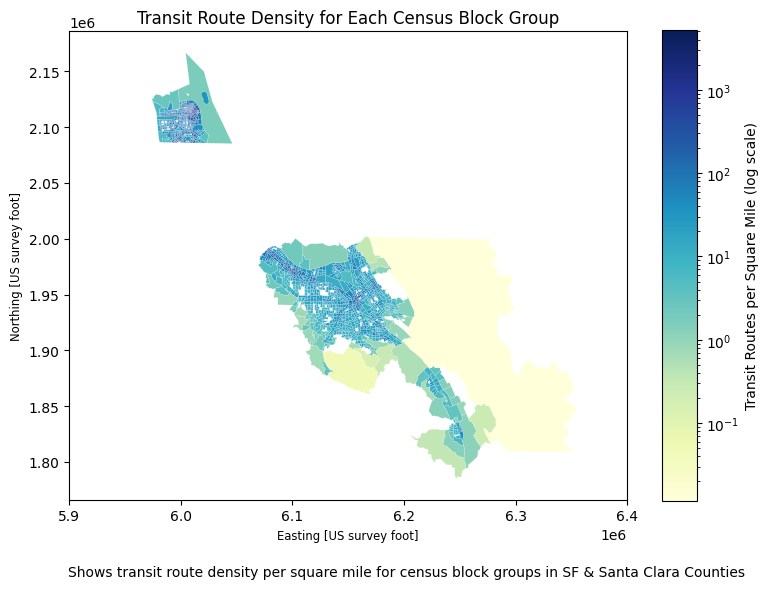

In [178]:
# Plotting transit density
fig, ax = map_route_density(sf_sc_bg)

ax.set_xlim(5900000, 6400000)

plt.title('Transit Route Density for Each Census Block Group')
plt.figtext(0.5,
            0.15,
            "Shows transit route density per square mile for census block groups in SF & Santa Clara Counties",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sf_sc_bg_route_density.png"),
    dpi=300,
    bbox_inches="tight")

## Interactive Map of Transit Route Density

In [179]:
# Making map interactive

# Converting route_densities to numpy array
route_densities = (
    sf_sc_bg["route_density"]
    .fillna(0)
    .to_numpy()
)

# Filtering for only positive values since log values can't be equal to 0
pos_route_densities = route_densities[route_densities > 0]

# Create function to normalize route_densities with a log scale
normalizer = LogNorm(
    1,
    pos_route_densities.max(),
    clip=True
    )

normalized_route_densities = normalizer(pos_route_densities)

# Creating continous color scale
colors = apply_continuous_cmap(normalized_route_densities, YlGnBu_9)

# Creating copy of block groups to conversion of crs
sf_sc_bg_4326 = sf_sc_bg.copy()
sf_sc_bg_4326 = sf_sc_bg.to_crs("4326")
sf_sc_bg_4326 = sf_sc_bg[sf_sc_bg['route_density'] > 0]

# Creating layer for lonboard map
layer = (
    PolygonLayer
    .from_geopandas(
      sf_sc_bg_4326[["geoid", "route_density", "geometry"]],
      get_fill_color=colors,
  )
)

# Setting default view to be in the center of the bay Area
view_state = {
    "longitude": -122.15642,
    "latitude":  37.55745,
    "zoom": 8,
}

# Loading map
interactive = Map(
    layer,
    view_state=view_state,
    basemap=MaplibreBasemap(style=CartoStyle.DarkMatter),
)
interactive

/usr/local/lib/python3.13/dist-packages/lonboard/_geoarrow/ops/reproject.py:116: UserWarning: Input being reprojected to EPSG:4326 CRS.
Lonboard is only able to render data in EPSG:4326 projection.
  warnings.warn(


## Route Density Maps Zooming In on Each County

In [180]:
# Filtering to SF County
sf_bg = sf_sc_bg[sf_sc_bg['countyfp'] == '075']

print("Block Groups w/ Route Densities in Both Counties:", len(sf_sc_bg))
print("Block Groups w/ Route Densities in SF County:", len(sf_bg))
print("Block Groups removed:", len(sf_sc_bg) - len(sf_bg))

Block Groups w/ Route Densities in Both Counties: 1854
Block Groups w/ Route Densities in SF County: 681
Block Groups removed: 1173


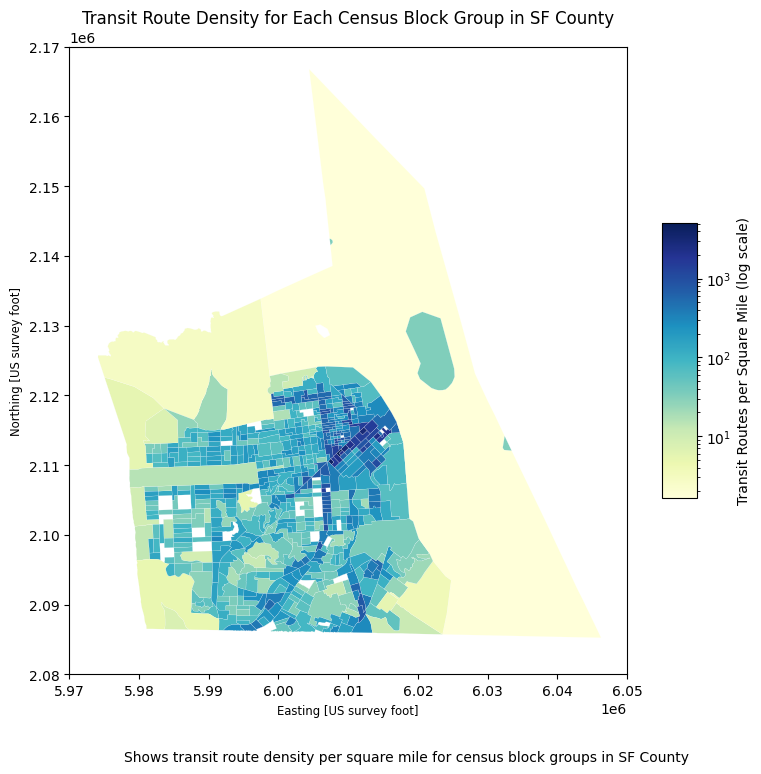

In [181]:
# Plotting only San Francisco county
fig, ax = map_route_density(sf_bg)

ax.set_xlim(5970000, 6050000)
ax.set_ylim(2080000, 2170000)

plt.title('Transit Route Density for Each Census Block Group in SF County')
plt.figtext(0.5,
            0.05,
            "Shows transit route density per square mile for census block groups in SF County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sf_bg_route_density.png"),
    dpi=300,
    bbox_inches="tight")

In [182]:
# Filtering to Santa Clara County
sc_bg = sf_sc_bg[sf_sc_bg['countyfp'] == '085']

print("Block Groups w/ Route Densities in Both Counties:", len(sf_sc_bg))
print("Block Groups w/ Route Densities in Santa Clara County:", len(sc_bg))
print("Block Groups removed:", len(sf_sc_bg) - len(sc_bg))

Block Groups w/ Route Densities in Both Counties: 1854
Block Groups w/ Route Densities in Santa Clara County: 1173
Block Groups removed: 681


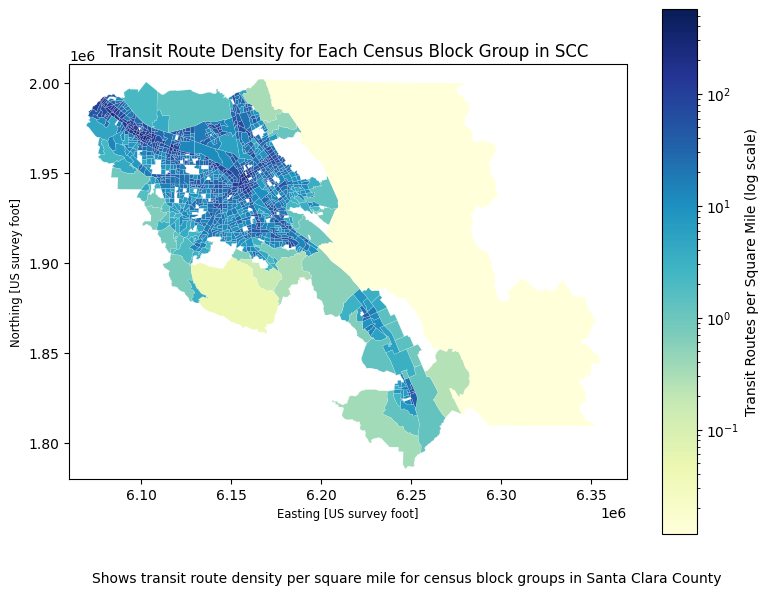

In [183]:
# Plotting only Santa Clara county
fig, ax = map_route_density(sc_bg)

ax.set_xlim(6060000, 6370000)
ax.set_ylim(1780000, 2010000)

plt.title('Transit Route Density for Each Census Block Group in SCC')
plt.figtext(0.5,
            0.15,
            "Shows transit route density per square mile for census block groups in Santa Clara County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sc_bg_route_density.png"),
    dpi=300,
    bbox_inches="tight")

## Calculating Route Density Statistics

In [184]:
# Calculating route density statistics
sf_sc_bg[['route_density']].describe()

,route_density
count,1854.000000
mean,115.563992
std,285.733664
min,0.000000
25%,11.475002
50%,35.048819
75%,98.441102
max,5139.491048


In [185]:
calc_stats(sf_sc_bg, 'countyfp', 'County')

Median route density: 35.04881901475981
------------------------------------------------------------
Route Density Average Per County
countyfp
075    256.041992
085     34.007710
Name: route_density, dtype: float64
------------------------------------------------------------
Route Density Median Per County
countyfp
075    123.299194
085     18.917674
Name: route_density, dtype: float64


## Transit Density in SB 79 Zones

In [186]:
# Loading in Tier 1 and Tier 2 polygons
sb79_tier_zones = gpd.read_file("data/raw/mtc_sb79_tod_zones.geojson")

sb79_tier_zones.head()

,OBJECTID,zone_id,zone_label,geometry
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((-122.41005 37.62829 0, -122.41011 ..."
1,2,79f5642a-6435-4716-a694-03d275e109bf,Tier 1 - 200ft,"POLYGON Z ((-122.41571 37.63717 0, -122.41577 ..."
2,3,823ebbcc-0305-4986-ac7e-deb4954d6e39,Tier 1 - 200ft,"POLYGON Z ((-122.44385 37.66357 0, -122.44392 ..."
3,4,c60319c0-2b8b-4645-8fd4-961eda2fdf6b,Tier 1 - 200ft,"POLYGON Z ((-122.46749 37.68288 0, -122.46755 ..."
4,5,1e3f5c82-2986-4b56-8776-6d69a7fef2c3,Tier 1 - 200ft,"POLYGON Z ((-122.46866 37.70547 0, -122.46872 ..."


In [187]:
# Checking info of sb79_tier_zones
sb79_tier_zones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 665 entries, 0 to 664
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    665 non-null    int32   
 1   zone_id     665 non-null    object  
 2   zone_label  665 non-null    object  
 3   geometry    665 non-null    geometry
dtypes: geometry(1), int32(1), object(2)
memory usage: 18.3+ KB


### Spatial Join of Transit Routes & SB 79 Zones

In [188]:
# Spatial join of transit routes & SB 79 Zones
sb79_tier_zones = sb79_tier_zones.to_crs('2227')
routes_zones = gpd.sjoin(sb79_tier_zones, transit_routes.drop(columns=["index_right"]), how = "left", predicate = "intersects")

routes_zones.head()

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,OBJECTID,zone_id,zone_label,geometry,index_right,objectid,shape_id,route_name,n_trips,route_type,route_leng,route_id,pct_route_,shn_route,agency,district_n,shape_leng,fipst,fipco,coname
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((6008568.343 2056881.526 0, 6008552...",23.0,262,p_1438438,Local Weekday,18.0,2,256991.99,Local Weekday,3.4,"84, 85, 87, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,98837.2001568155,06,085,
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((6008568.343 2056881.526 0, 6008552...",115.0,1220,p_1438273,Local Weekend,34.0,2,256979.99,Local Weekend,3.4,"84, 85, 87, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,98832.57950343884,06,085,
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((6008568.343 2056881.526 0, 6008552...",116.0,1220,p_1438273,Local Weekend,34.0,2,256979.99,Local Weekend,3.4,"84, 85, 87, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,98832.57950343884,06,075,
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((6008568.343 2056881.526 0, 6008552...",24.0,262,p_1438438,Local Weekday,18.0,2,256991.99,Local Weekday,3.4,"84, 85, 87, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,98837.2001568155,06,075,
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((6008568.343 2056881.526 0, 6008552...",127.0,1307,p_1438280,Local Weekend,34.0,2,257006.1,Local Weekend,3.4,"84, 85, 87, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,98842.60685657705,06,075,


In [189]:
# Looking at data types in routes_zones and length
routes_zones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 8723 entries, 0 to 664
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   OBJECTID     8723 non-null   int32   
 1   zone_id      8723 non-null   object  
 2   zone_label   8723 non-null   object  
 3   geometry     8723 non-null   geometry
 4   index_right  8609 non-null   float64 
 5   objectid     8609 non-null   object  
 6   shape_id     8609 non-null   object  
 7   route_name   8609 non-null   object  
 8   n_trips      8609 non-null   object  
 9   route_type   8609 non-null   object  
 10  route_leng   8609 non-null   object  
 11  route_id     8609 non-null   object  
 12  pct_route_   8609 non-null   object  
 13  shn_route    8609 non-null   object  
 14  agency       8609 non-null   object  
 15  district_n   8609 non-null   object  
 16  shape_leng   8609 non-null   object  
 17  fipst        8609 non-null   object  
 18  fipco        8609 non-null

In [190]:
print("Number of SB 79 zones:", len(sb79_tier_zones))
print("Transit routes in SF & SCC:", len(transit_routes))
print("Spatial join:", len(routes_zones))

Number of SB 79 zones: 665
Transit routes in SF & SCC: 501
Spatial join: 8723


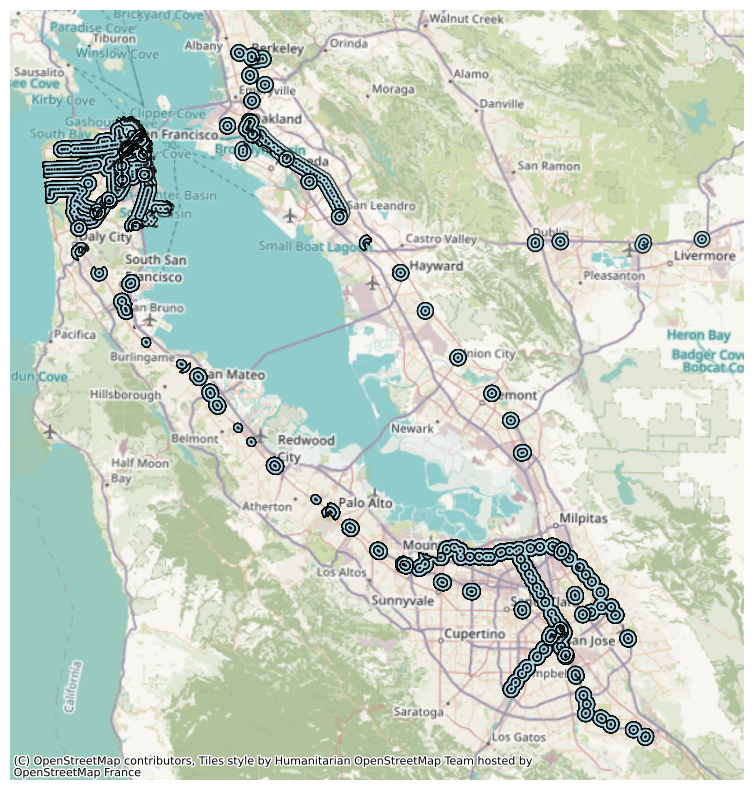

In [191]:
# Looking at spatial join as a map for a visual check
fig, ax = plt.subplots(figsize=(8, 8))
routes_zones.plot(edgecolor="black", facecolor="lightblue", alpha=0.7, legend=True, ax=ax)
cx.add_basemap(ax, crs=sf_sc_bg.crs)
ax.set_axis_off()

plt.tight_layout()
plt.show()

### Calculate Transit Route Density of SB 79 Zones

In [192]:
# Counting number of routes in each zone and calculating transit route density
calculate_route_density(sb79_tier_zones, routes_zones, 'zone_id')


,OBJECTID,zone_id,zone_label,geometry,route_count,area_sqmile,route_density
0,1,764ca928-8bd7-4c6e-83d2-835dca264eed,Tier 1 - 200ft,"POLYGON Z ((6008568.343 2056881.526 0, 6008552...",20,0.024551,814.645819
1,2,79f5642a-6435-4716-a694-03d275e109bf,Tier 1 - 200ft,"POLYGON Z ((6006996.944 2060148.445 0, 6006979...",4,0.007015,570.175322
2,3,823ebbcc-0305-4986-ac7e-deb4954d6e39,Tier 1 - 200ft,"POLYGON Z ((5999049.156 2069927.746 0, 5999029...",5,0.006607,756.791508
3,4,c60319c0-2b8b-4645-8fd4-961eda2fdf6b,Tier 1 - 200ft,"POLYGON Z ((5992355.406 2077100.256 0, 5992339...",0,0.004251,0.000000
4,5,1e3f5c82-2986-4b56-8776-6d69a7fef2c3,Tier 1 - 200ft,"POLYGON Z ((5992191.47 2085330.232 0, 5992174....",30,0.009395,3193.164223


In [193]:
# Checking info of sb79_tiers_zones
sb79_tier_zones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 665 entries, 0 to 664
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   OBJECTID       665 non-null    int32   
 1   zone_id        665 non-null    object  
 2   zone_label     665 non-null    object  
 3   geometry       665 non-null    geometry
 4   route_count    665 non-null    int64   
 5   area_sqmile    665 non-null    float64 
 6   route_density  665 non-null    float64 
dtypes: float64(2), geometry(1), int32(1), int64(1), object(2)
memory usage: 33.9+ KB


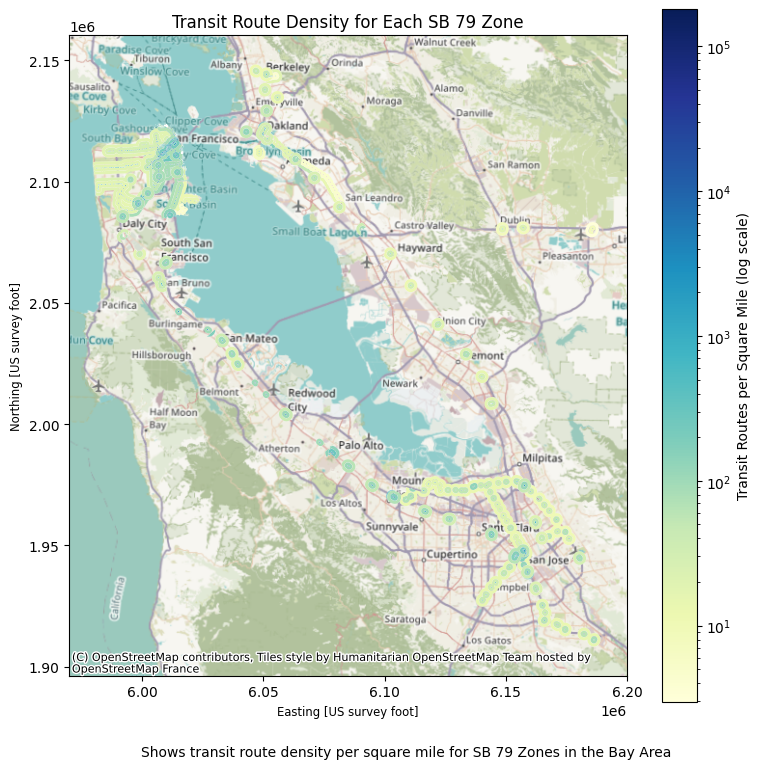

In [194]:
# Plotting transit density
fig, ax = map_route_density(sb79_tier_zones)

ax.set_xlim(5970000, 6200000)
cx.add_basemap(ax, crs=routes_zones.crs)

plt.title('Transit Route Density for Each SB 79 Zone')
plt.figtext(0.5,
            0.05,
            "Shows transit route density per square mile for SB 79 Zones in the Bay Area",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sf_sc_zones_route_density.png"),
    dpi=300,
    bbox_inches="tight")

### Route Density Maps Zooming In on Each County

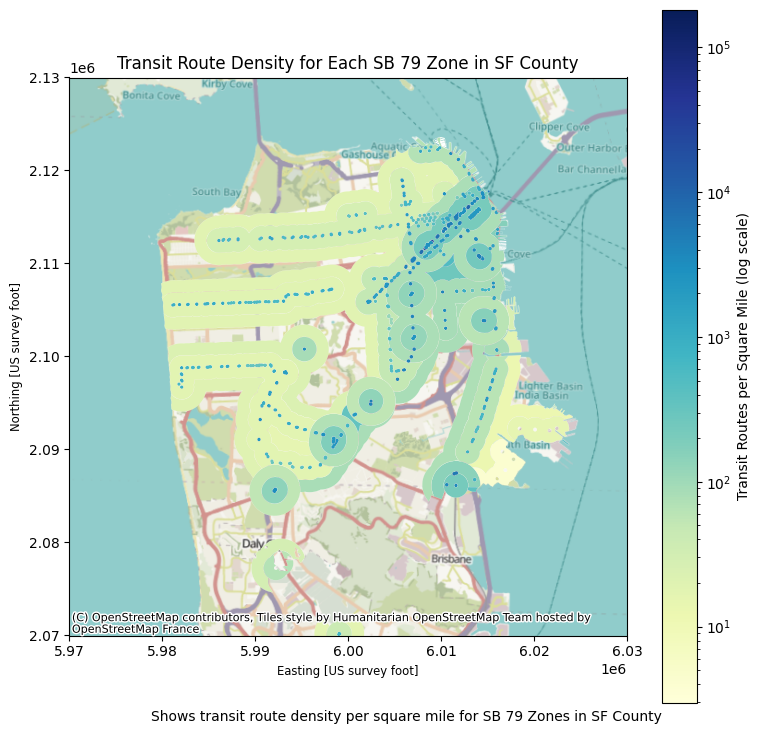

In [195]:
# Zooming in on SF County
fig, ax = map_route_density(sb79_tier_zones)

ax.set_xlim(5970000, 6030000)
ax.set_ylim(2070000, 2130000)
cx.add_basemap(ax, crs=routes_zones.crs)

plt.title('Transit Route Density for Each SB 79 Zone in SF County')
plt.figtext(0.5,
            0.09,
            "Shows transit route density per square mile for SB 79 Zones in SF County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sf_zones_route_density.png"),
    dpi=300,
    bbox_inches="tight")

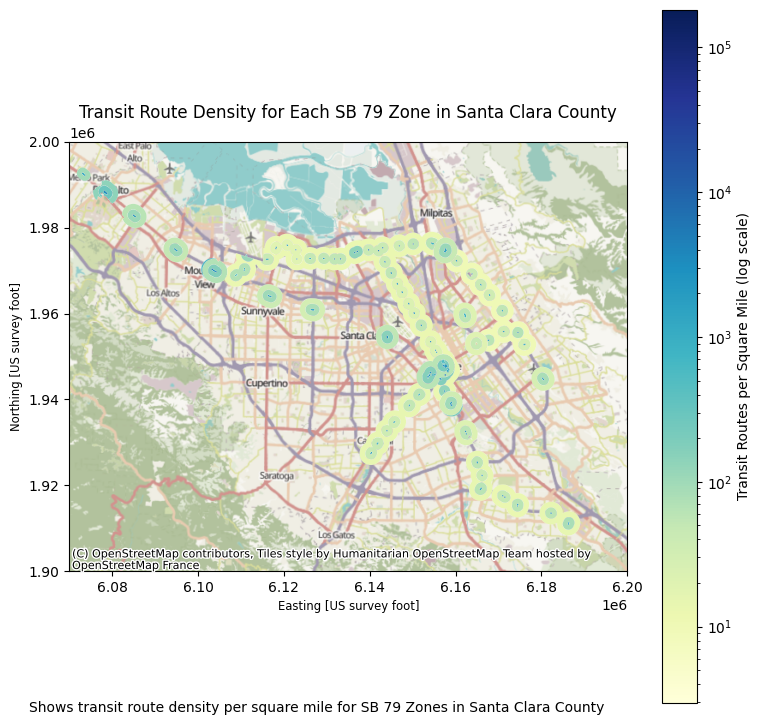

In [196]:
# Zooming in on Santa Clara County
fig, ax = map_route_density(sb79_tier_zones)

ax.set_xlim(6070000, 6200000)
ax.set_ylim(1900000, 2000000)
cx.add_basemap(ax, crs=routes_zones.crs)

plt.title('Transit Route Density for Each SB 79 Zone in Santa Clara County')
plt.figtext(0.4,
            0.1,
            "Shows transit route density per square mile for SB 79 Zones in Santa Clara County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sc_zones_route_density.png"),
    dpi=300,
    bbox_inches="tight")

### Calculating Route Density Statistics

In [197]:
# Calculating route density statistics
sb79_tier_zones[['route_density']].describe()

,route_density
count,665.000000
mean,1627.958258
std,9580.158057
min,0.000000
25%,25.198999
50%,444.145377
75%,1332.441945
max,181405.243567


In [198]:
calc_stats(sb79_tier_zones, 'zone_label', 'Tier Type')

Median route density: 444.1453771976328
------------------------------------------------------------
Route Density Average Per Tier Type
zone_label
Tier 1 - 200ft           1779.615025
Tier 1 - Half Mile        874.298592
Tier 1 - Quarter Mile      91.705794
Tier 2 - 200ft           2580.562896
Tier 2 - Half Mile         49.198929
Tier 2 - Quarter Mile     314.774934
Name: route_density, dtype: float64
------------------------------------------------------------
Route Density Median Per Tier Type
zone_label
Tier 1 - 200ft           1554.578564
Tier 1 - Half Mile         27.633503
Tier 1 - Quarter Mile      90.083166
Tier 2 - 200ft            991.757067
Tier 2 - Half Mile          6.363162
Tier 2 - Quarter Mile      42.616927
Name: route_density, dtype: float64


## Examining Census Block Transit Density Excluding SB 79 Zones

In [199]:
# Excluding SB 79 zones from transit routes & census blocks dataset
sb79_tier_zones_all = sb79_tier_zones.geometry.union_all()
routes_sf_sc_nozones = sf_sc_bg.copy()

routes_sf_sc_nozones['geometry'] = (routes_sf_sc_nozones.geometry.difference(sb79_tier_zones_all))

routes_sf_sc_nozones = routes_sf_sc_nozones[~routes_sf_sc_nozones.geometry.is_empty]

# Display data frame
routes_sf_sc_nozones.head()

,statefp,countyfp,tractce,blkgrpce,geoid,geoidfq,namelsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry,route_count,area_sqmile,route_density
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,0,+37.2959111,-121.8469592,"POLYGON Z ((6168271.645 1932624.062 0, 6168279...",8,0.162324,49.283999
18,06,085,503218,2,060855032182,1500000US060855032182,Block Group 2,G5030,S,183484,0,+37.2804060,-121.8340967,"POLYGON Z ((6172615.108 1927190.569 0, 6172640...",14,0.070838,197.633611
19,06,085,504424,2,060855044242,1500000US060855044242,Block Group 2,G5030,S,370668,0,+37.4448467,-121.8829137,"POLYGON Z ((6158933.18 1988518.026 0, 6158953....",4,0.143099,27.952672
20,06,085,512309,1,060855123091,1500000US060855123091,Block Group 1,G5030,S,2908327,0,+37.1388946,-121.5954451,"POLYGON Z ((6238118.981 1871947.517 0, 6238605...",0,1.122875,0.000000
21,06,085,512036,2,060855120362,1500000US060855120362,Block Group 2,G5030,S,472203,0,+37.2388299,-121.8108181,"POLYGON Z ((6178253.057 1912946.682 0, 6178349...",5,0.182307,27.426330


In [200]:
# Looking at data types in routes_sf_sc_nozones and length
routes_sf_sc_nozones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 1638 entries, 17 to 25507
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   statefp        1638 non-null   object  
 1   countyfp       1638 non-null   object  
 2   tractce        1638 non-null   object  
 3   blkgrpce       1638 non-null   object  
 4   geoid          1638 non-null   object  
 5   geoidfq        1638 non-null   object  
 6   namelsad       1638 non-null   object  
 7   mtfcc          1638 non-null   object  
 8   funcstat       1638 non-null   object  
 9   aland          1638 non-null   int64   
 10  awater         1638 non-null   int64   
 11  intptlat       1638 non-null   object  
 12  intptlon       1638 non-null   object  
 13  geometry       1638 non-null   geometry
 14  route_count    1638 non-null   int64   
 15  area_sqmile    1638 non-null   float64 
 16  route_density  1638 non-null   float64 
dtypes: float64(2), geometry(1), 

### Calculating Transit Route Density

In [201]:
# Counting number of routes in each zone & calculating transit route density
# Not using calculate_route_density function due to no 'index_right' col being present
route_counts = routes_sf_sc_nozones.groupby('geoid').size()

routes_sf_sc_nozones["route_count"] = (routes_sf_sc_nozones["geoid"].map(route_counts).fillna(0))

In [202]:
# Calculating transit route density
routes_sf_sc_nozones['area_sqmile'] = routes_sf_sc_nozones.geometry.area / 27878400

routes_sf_sc_nozones['route_density'] = (routes_sf_sc_nozones['route_count'] / routes_sf_sc_nozones['area_sqmile'])

routes_sf_sc_nozones.head()

,statefp,countyfp,tractce,blkgrpce,geoid,geoidfq,namelsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry,route_count,area_sqmile,route_density
17,06,085,503222,2,060855032222,1500000US060855032222,Block Group 2,G5030,S,420454,0,+37.2959111,-121.8469592,"POLYGON Z ((6168271.645 1932624.062 0, 6168279...",1,0.162324,6.160500
18,06,085,503218,2,060855032182,1500000US060855032182,Block Group 2,G5030,S,183484,0,+37.2804060,-121.8340967,"POLYGON Z ((6172615.108 1927190.569 0, 6172640...",1,0.070838,14.116686
19,06,085,504424,2,060855044242,1500000US060855044242,Block Group 2,G5030,S,370668,0,+37.4448467,-121.8829137,"POLYGON Z ((6158933.18 1988518.026 0, 6158953....",1,0.143099,6.988168
20,06,085,512309,1,060855123091,1500000US060855123091,Block Group 1,G5030,S,2908327,0,+37.1388946,-121.5954451,"POLYGON Z ((6238118.981 1871947.517 0, 6238605...",1,1.122875,0.890571
21,06,085,512036,2,060855120362,1500000US060855120362,Block Group 2,G5030,S,472203,0,+37.2388299,-121.8108181,"POLYGON Z ((6178253.057 1912946.682 0, 6178349...",1,0.087155,11.473831


In [203]:
print("Number of SB 79 zones:", len(sb79_tier_zones))
print("Number of block groups:", len(sf_sc_bg))
print("Block groups excluding SB 79 zones:", len(routes_sf_sc_nozones))
print("Number of block groups removed:", len(sf_sc_bg) - len(routes_sf_sc_nozones))

Number of SB 79 zones: 665
Number of block groups: 1854
Block groups excluding SB 79 zones: 1638
Number of block groups removed: 216


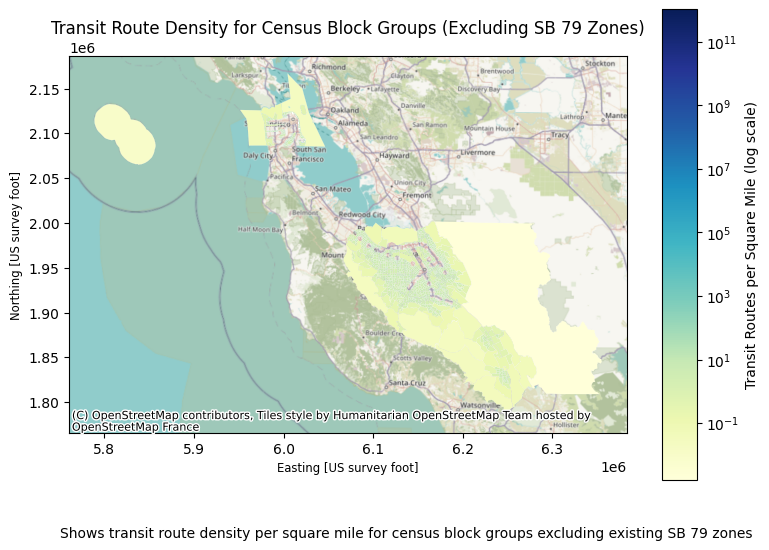

In [204]:
# Plotting transit density
fig, ax = map_route_density(routes_sf_sc_nozones)

cx.add_basemap(ax, crs=routes_sf_sc_nozones.crs)

plt.title('Transit Route Density for Census Block Groups (Excluding SB 79 Zones)')
plt.figtext(0.5,
            0.17,
            "Shows transit route density per square mile for census block groups excluding existing SB 79 zones",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "route_density_nosb79.png"),
    dpi=300,
    bbox_inches="tight")

### Route Density Maps Zooming In on Each County

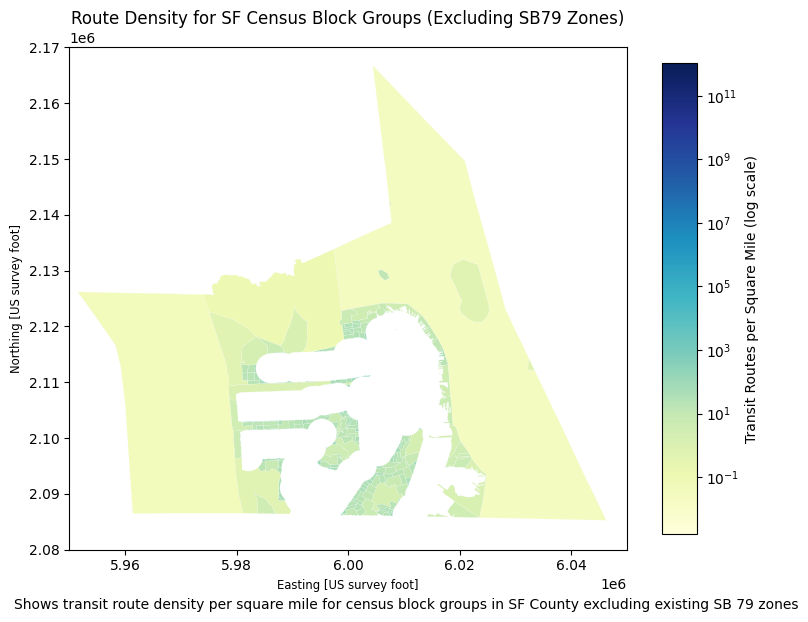

In [205]:
# Plotting only San Francisco county
fig, ax = map_route_density(routes_sf_sc_nozones)

ax.set_xlim(5950000, 6050000)
ax.set_ylim(2080000, 2170000)

plt.title('Route Density for SF Census Block Groups (Excluding SB79 Zones)')
plt.figtext(0.5,
            0.15,
            "Shows transit route density per square mile for census block groups in SF County excluding existing SB 79 zones",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sf_route_density_nosb79.png"),
    dpi=300,
    bbox_inches="tight")

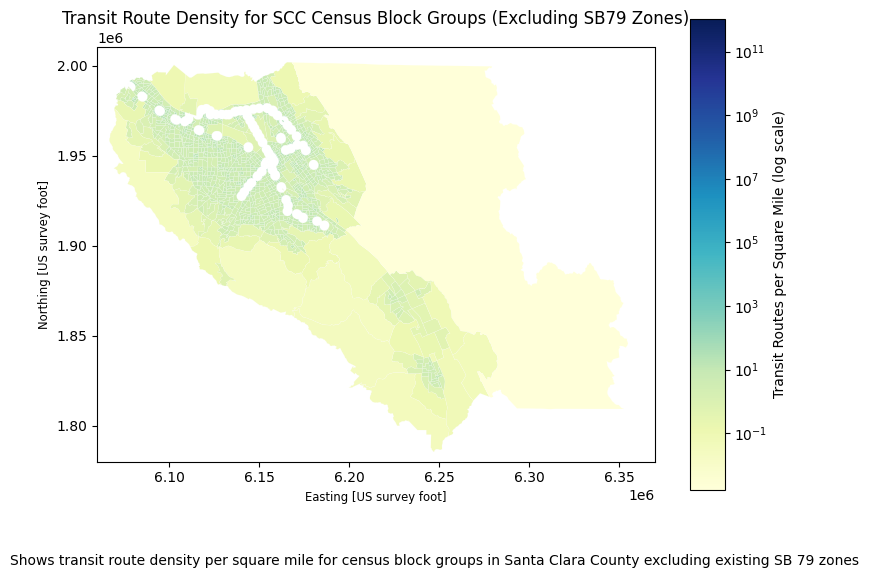

In [206]:
# Plotting only Santa Clara County
fig, ax = map_route_density(routes_sf_sc_nozones)

ax.set_xlim(6060000, 6370000)
ax.set_ylim(1780000, 2010000)

plt.title('Transit Route Density for SCC Census Block Groups (Excluding SB79 Zones)')
plt.figtext(0.5,
            0.15,
            "Shows transit route density per square mile for census block groups in Santa Clara County excluding existing SB 79 zones",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "sc_route_density_nosb79.png"),
    dpi=300,
    bbox_inches="tight")

### Calculating Route Density Statistics

In [207]:
# Calculating route density statistics
routes_sf_sc_nozones[['route_density']].describe()

,route_density
count,1.638000e+03
mean,5.276423e+09
std,4.098578e+10
min,1.683347e-03
25%,4.774464e+00
50%,9.309329e+00
75%,9.639465e+01
max,1.025071e+12


In [208]:
calc_stats(routes_sf_sc_nozones, 'countyfp', 'County')

Median route density: 9.30932897623767
------------------------------------------------------------
Route Density Average Per County
countyfp
075    1.564138e+10
085    6.961339e+08
Name: route_density, dtype: float64
------------------------------------------------------------
Route Density Median Per County
countyfp
075    1.427016e+09
085    6.467980e+00
Name: route_density, dtype: float64


## Visualizing Distributions of Route Density in Each Census Block

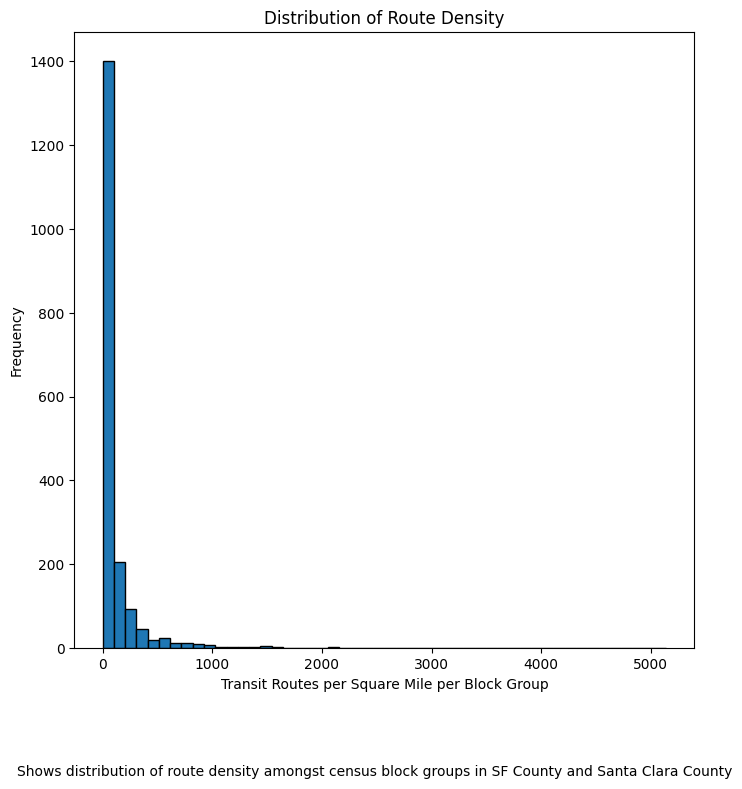

In [212]:
# Route density histogram
fig, ax = create_histogram(sf_sc_bg)

plt.title('Distribution of Route Density')
plt.figtext(0.5,
            -0.05,
            "Shows distribution of route density amongst census block groups in SF County and Santa Clara County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "route_density_hist.png"),
    dpi=300,
    bbox_inches="tight")

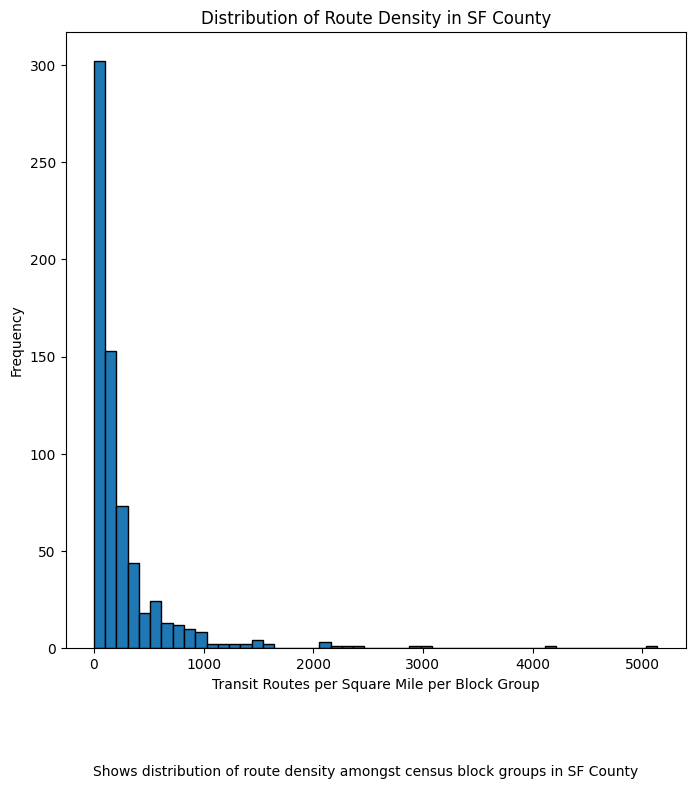

In [213]:
# Route density histogram for SF County
fig, ax = create_histogram(sf_bg)

plt.title('Distribution of Route Density in SF County')
plt.figtext(0.5,
            -0.05,
            "Shows distribution of route density amongst census block groups in SF County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "route_density_sf_hist.png"),
    dpi=300,
    bbox_inches="tight")

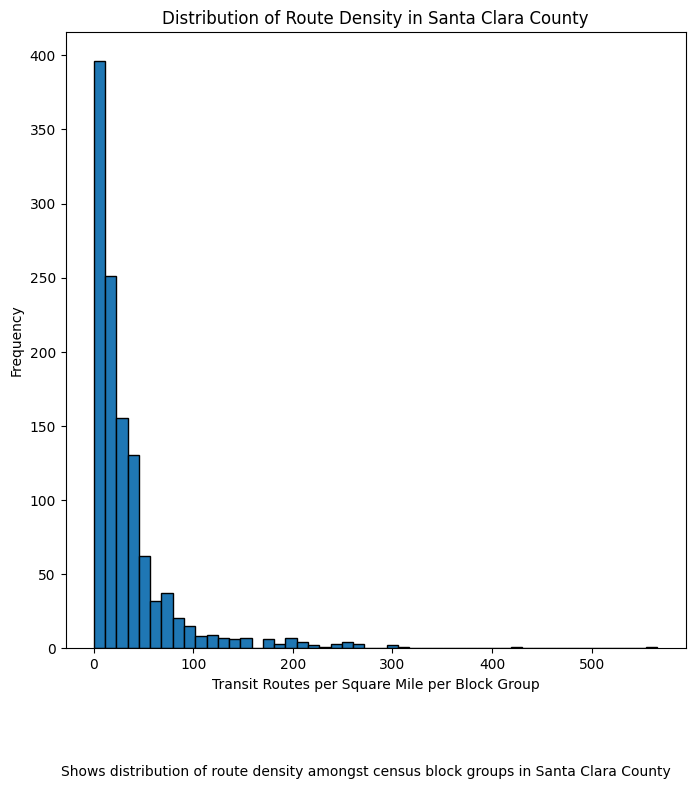

In [214]:
# Route density histogram for Santa Clara County
fig, ax = create_histogram(sc_bg)

plt.title('Distribution of Route Density in Santa Clara County')
plt.figtext(0.5,
            -0.05,
            "Shows distribution of route density amongst census block groups in Santa Clara County",
            wrap=True,
            horizontalalignment='center',
            fontsize=10)

fig.savefig(os.path.join(visualizations_folder, "route_density_sc_hist.png"),
    dpi=300,
    bbox_inches="tight")